# Explaining the classifiers

What drives the predictions of the 8 classifiers in `training/classifiers`? Label `SCREENING_12M_FLAG`
(screened within 12 months), official split, every model in its default setting (as in `compare.py`).
Numbers come from `run.py` (results in `results/`).

**Tools**
- **Tree drawings:** the real decision tree (depth 8) is too big to read, so small depth-3 / depth-4 trees are drawn
  instead. Their test ROC AUC shows how much of the full tree's accuracy they keep.
- **Permutation importance:** drop in test ROC AUC when one feature's values are shuffled (20k test rows,
  5 repeats). It works for every model, so models can be compared directly. Correlated features share their
  importance: shuffling `INVITATION_SEQUENCE` hurts less because `PRIOR_INVITATION_COUNT` still carries similar
  information.
- **Partial dependence:** the average predicted response rate when one feature is set to a value for everyone
  (4k train rows). It shows the *direction and shape* of an effect, holding the other features as they are.
- **Logistic-regression odds ratios:** the most directly readable model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display


RESULTS = Path("results")
models = pd.read_csv(RESULTS / "models.csv")
perm = pd.read_csv(RESULTS / "permutation_importance.csv")
pdp = pd.read_csv(RESULTS / "partial_dependence.csv")
coef = pd.read_csv(RESULTS / "lr_coefficients.csv")
tree_imp = pd.read_csv(RESULTS / "tree_importance.csv")
codes = pd.read_csv(RESULTS / "category_codes.csv")

INK2, GRID, BLUE, GRAY = "#52514e", "#e4e3df", "#2a78d6", "#a3a29d"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left", "legend.frameon": False,
})
models.style.format({"test_roc_auc": "{:.4f}"}).hide(axis="index")

model,test_roc_auc
gradient boosting,0.8412
random forest,0.8400
MLP,0.8397
decision tree,0.8364
spline logistic regression,0.8346
logistic regression,0.8319
kNN,0.8314
naive Bayes,0.7998
decision tree depth 3,0.8084
decision tree depth 4,0.8225


## 1. The decision tree, drawn

Each box shows the split rule, the share of training rows that reach it (`samples`), and
`value = [share not screened, share screened]`. Orange boxes are mostly "not screened" and blue boxes mostly
"screened"; the darker, the clearer. Left = rule true, right = rule false. Rows with a missing value go to the
side the tree learned for them (sklearn does not draw this).

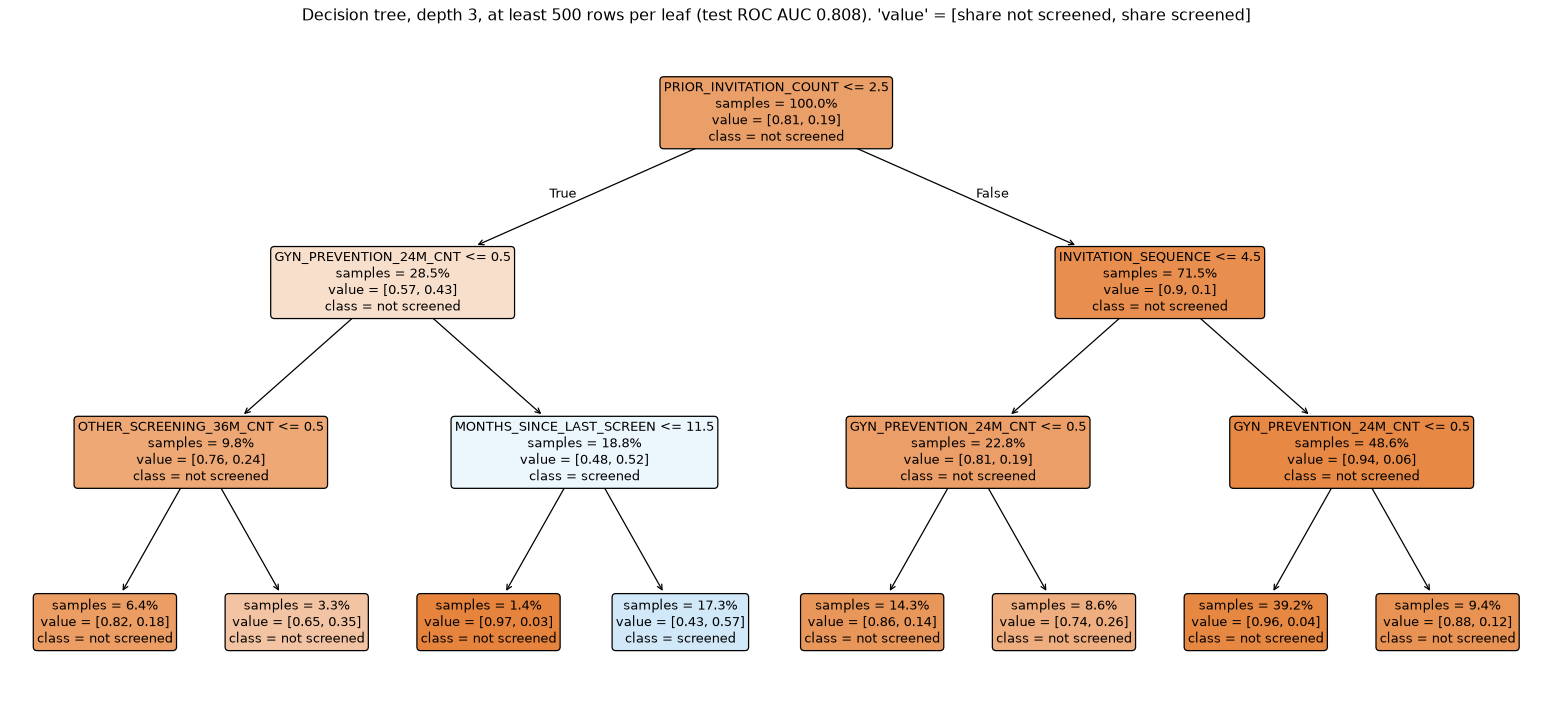

In [2]:
display(Image(str(RESULTS / "tree_depth3.png")))

A slightly deeper version (depth 4, 16 leaves):

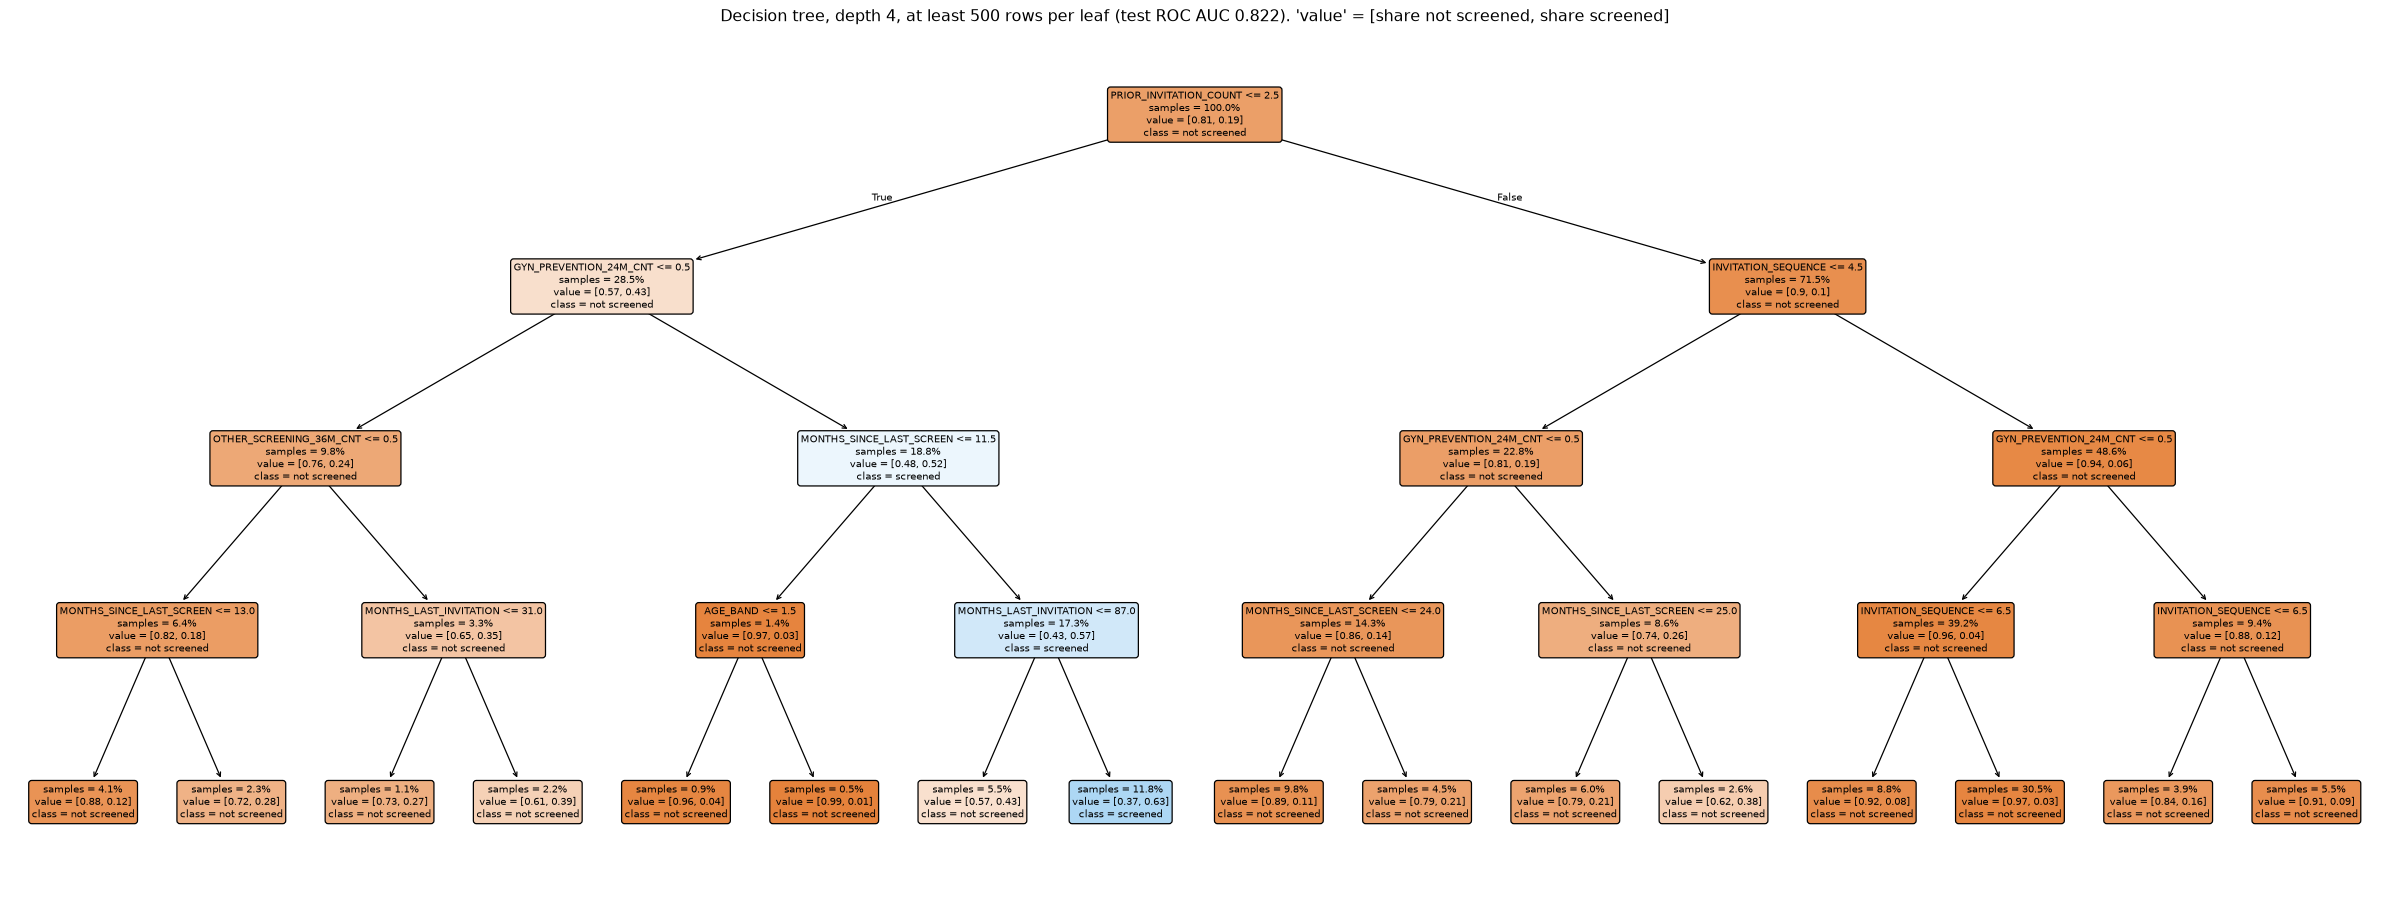

In [3]:
display(Image(str(RESULTS / "tree_depth4.png")))

**Integer codes in the drawings.** Categorical columns are stored as codes in the trees. `AGE_BAND <= 1.5` means
code 0 or 1:

In [4]:
age = codes[codes.column == "AGE_BAND"].set_index("code").category
print("AGE_BAND codes:", ", ".join(f"{c} = {v}" for c, v in age.items()))
for col in ["GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]:
    m = codes[codes.column == col].set_index("code").category
    print(f"{col} codes:", ", ".join(f"{c} = {v}" for c, v in m.items()), "(missing = not registered)")

AGE_BAND codes: 0 = 40-44, 1 = 45-49, 2 = 50-54, 3 = 55-59, 4 = 60-64, 5 = 65-69, 6 = 70-74
GP_REG_DURATION_BAND codes: 0 = 2-5, 1 = <2, 2 = >5, 3 = nan (missing = not registered)
GYN_REG_DURATION_BAND codes: 0 = 2-5, 1 = <2, 2 = >5, 3 = nan (missing = not registered)


**The real tree (depth 8), top 4 levels as rules**, and which features its splits use (impurity importance: how
much each feature's splits reduce the error, summed over the tree):

In [5]:
print((RESULTS / "tree_rules.txt").read_text(encoding="utf8")[:6000])

Real decision tree (depth 8, >=500 rows per leaf), top 4 levels; deeper branches are shown as 'truncated branch'. 'class: 1' = majority screened.

|--- PRIOR_INVITATION_COUNT <= 2.50
|   |--- GYN_PREVENTION_24M_CNT <= 0.50
|   |   |--- OTHER_SCREENING_36M_CNT <= 0.50
|   |   |   |--- MONTHS_SINCE_LAST_SCREEN <= 13.00
|   |   |   |   |--- DENTAL_PREVENTION_24M_CNT <= 0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- DENTAL_PREVENTION_24M_CNT >  0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- MONTHS_SINCE_LAST_SCREEN >  13.00
|   |   |   |   |--- MONTHS_SINCE_LAST_SCREEN <= 46.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- MONTHS_SINCE_LAST_SCREEN >  46.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |--- OTHER_SCREENING_36M_CNT >  0.50
|   |   |   |--- MONTHS_LAST_INVITATION <= 31.00
|   |   |   |   |--- DENTAL_PREVENTION_24M_CNT <= 0.50
|   |   |   |   |   |--- truncated branch of dept

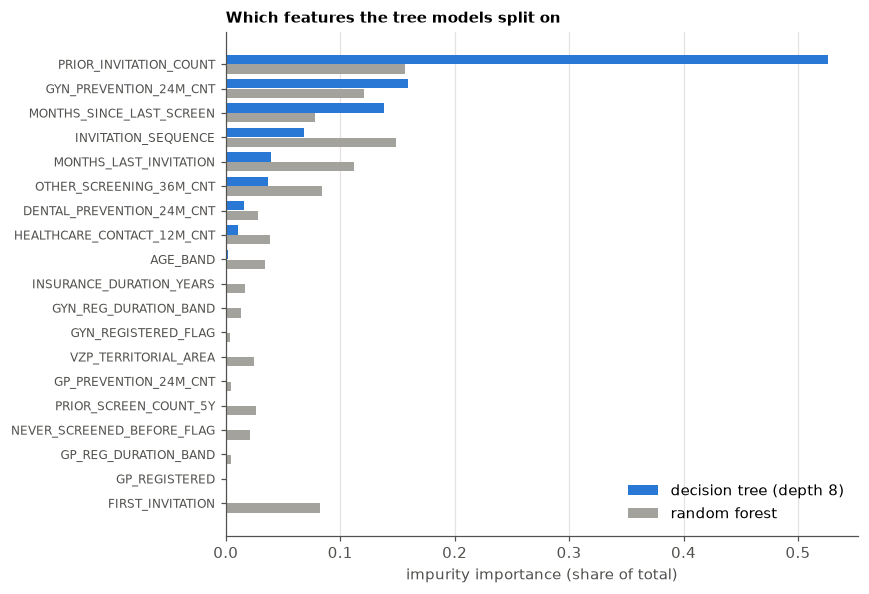

In [6]:
ti = tree_imp.pivot(index="feature", columns="model", values="importance").fillna(0)
ti = ti.sort_values("decision tree")
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(ti))
ax.barh(y + 0.2, ti["decision tree"], height=0.38, color=BLUE, label="decision tree (depth 8)")
ax.barh(y - 0.2, ti["random forest"], height=0.38, color=GRAY, label="random forest")
ax.set_yticks(y, ti.index, fontsize=8)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_xlabel("impurity importance (share of total)")
ax.set_title("Which features the tree models split on")
plt.tight_layout(); plt.show()

## 2. Driving predictors of every model

Permutation importance of each model, as a **share of that model's total** so that models of different strength
are comparable (each row sums to 100%).

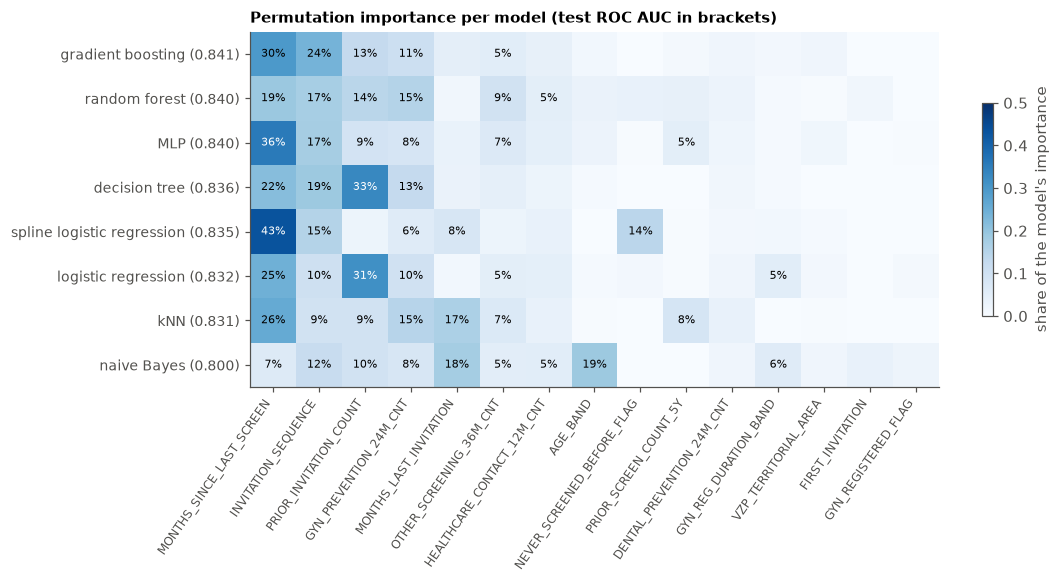

In [7]:
order = models.model[~models.model.str.startswith("decision tree depth")].tolist()
imp = perm.pivot(index="model", columns="feature", values="importance").clip(lower=0).loc[order]
share = imp.div(imp.sum(axis=1), axis=0)
cols = share.mean().sort_values(ascending=False).index
cols = [c for c in cols if share[c].max() >= 0.02]
share = share[cols]

fig, ax = plt.subplots(figsize=(1 + 0.62 * len(cols), 0.45 * len(share) + 1.8))
im = ax.imshow(share.to_numpy(), cmap="Blues", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=55, ha="right", fontsize=8)
auc = models.set_index("model").test_roc_auc
ax.set_yticks(range(len(share)), [f"{m} ({auc[m]:.3f})" for m in share.index], fontsize=9)
ax.grid(False)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iat[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.3 else "black")
fig.colorbar(im, ax=ax, shrink=0.6, label="share of the model's importance")
ax.set_title("Permutation importance per model (test ROC AUC in brackets)")
plt.tight_layout(); plt.show()

In [8]:
pd.set_option("display.max_colwidth", None)
top = (share.stack().rename("share").reset_index().sort_values("share", ascending=False)
       .groupby("model", sort=False).head(5))
top.groupby("model", sort=False).apply(
    lambda t: ", ".join(f"{f} ({s:.0%})" for f, s in zip(t.feature, t.share, strict=True)), include_groups=False
).reindex(order).to_frame("top 5 predictors")

,top 5 predictors
model,
gradient boosting,"MONTHS_SINCE_LAST_SCREEN (30%), INVITATION_SEQUENCE (24%), PRIOR_INVITATION_COUNT (13%), GYN_PREVENTION_24M_CNT (11%), OTHER_SCREENING_36M_CNT (5%)"
random forest,"MONTHS_SINCE_LAST_SCREEN (19%), INVITATION_SEQUENCE (17%), GYN_PREVENTION_24M_CNT (15%), PRIOR_INVITATION_COUNT (14%), OTHER_SCREENING_36M_CNT (9%)"
MLP,"MONTHS_SINCE_LAST_SCREEN (36%), INVITATION_SEQUENCE (17%), PRIOR_INVITATION_COUNT (9%), GYN_PREVENTION_24M_CNT (8%), OTHER_SCREENING_36M_CNT (7%)"
decision tree,"PRIOR_INVITATION_COUNT (33%), MONTHS_SINCE_LAST_SCREEN (22%), INVITATION_SEQUENCE (19%), GYN_PREVENTION_24M_CNT (13%), OTHER_SCREENING_36M_CNT (4%)"
spline logistic regression,"MONTHS_SINCE_LAST_SCREEN (43%), INVITATION_SEQUENCE (15%), NEVER_SCREENED_BEFORE_FLAG (14%), MONTHS_LAST_INVITATION (8%), GYN_PREVENTION_24M_CNT (6%)"
logistic regression,"PRIOR_INVITATION_COUNT (31%), MONTHS_SINCE_LAST_SCREEN (25%), INVITATION_SEQUENCE (10%), GYN_PREVENTION_24M_CNT (10%), GYN_REG_DURATION_BAND (5%)"
kNN,"MONTHS_SINCE_LAST_SCREEN (26%), MONTHS_LAST_INVITATION (17%), GYN_PREVENTION_24M_CNT (15%), PRIOR_INVITATION_COUNT (9%), INVITATION_SEQUENCE (9%)"
naive Bayes,"AGE_BAND (19%), MONTHS_LAST_INVITATION (18%), INVITATION_SEQUENCE (12%), PRIOR_INVITATION_COUNT (10%), GYN_PREVENTION_24M_CNT (8%)"


## 3. Direction of the effects (partial dependence)

How the average predicted response changes when one feature is set to a value for everyone, per model.
`MONTHS_SINCE_LAST_SCREEN` is shown only for women screened before, and `MONTHS_LAST_INVITATION` only for repeat
invitations, because the values don't exist for the others.
Lines are broken where no women have values (e.g. almost nobody is invited 2–35 months after a screen).

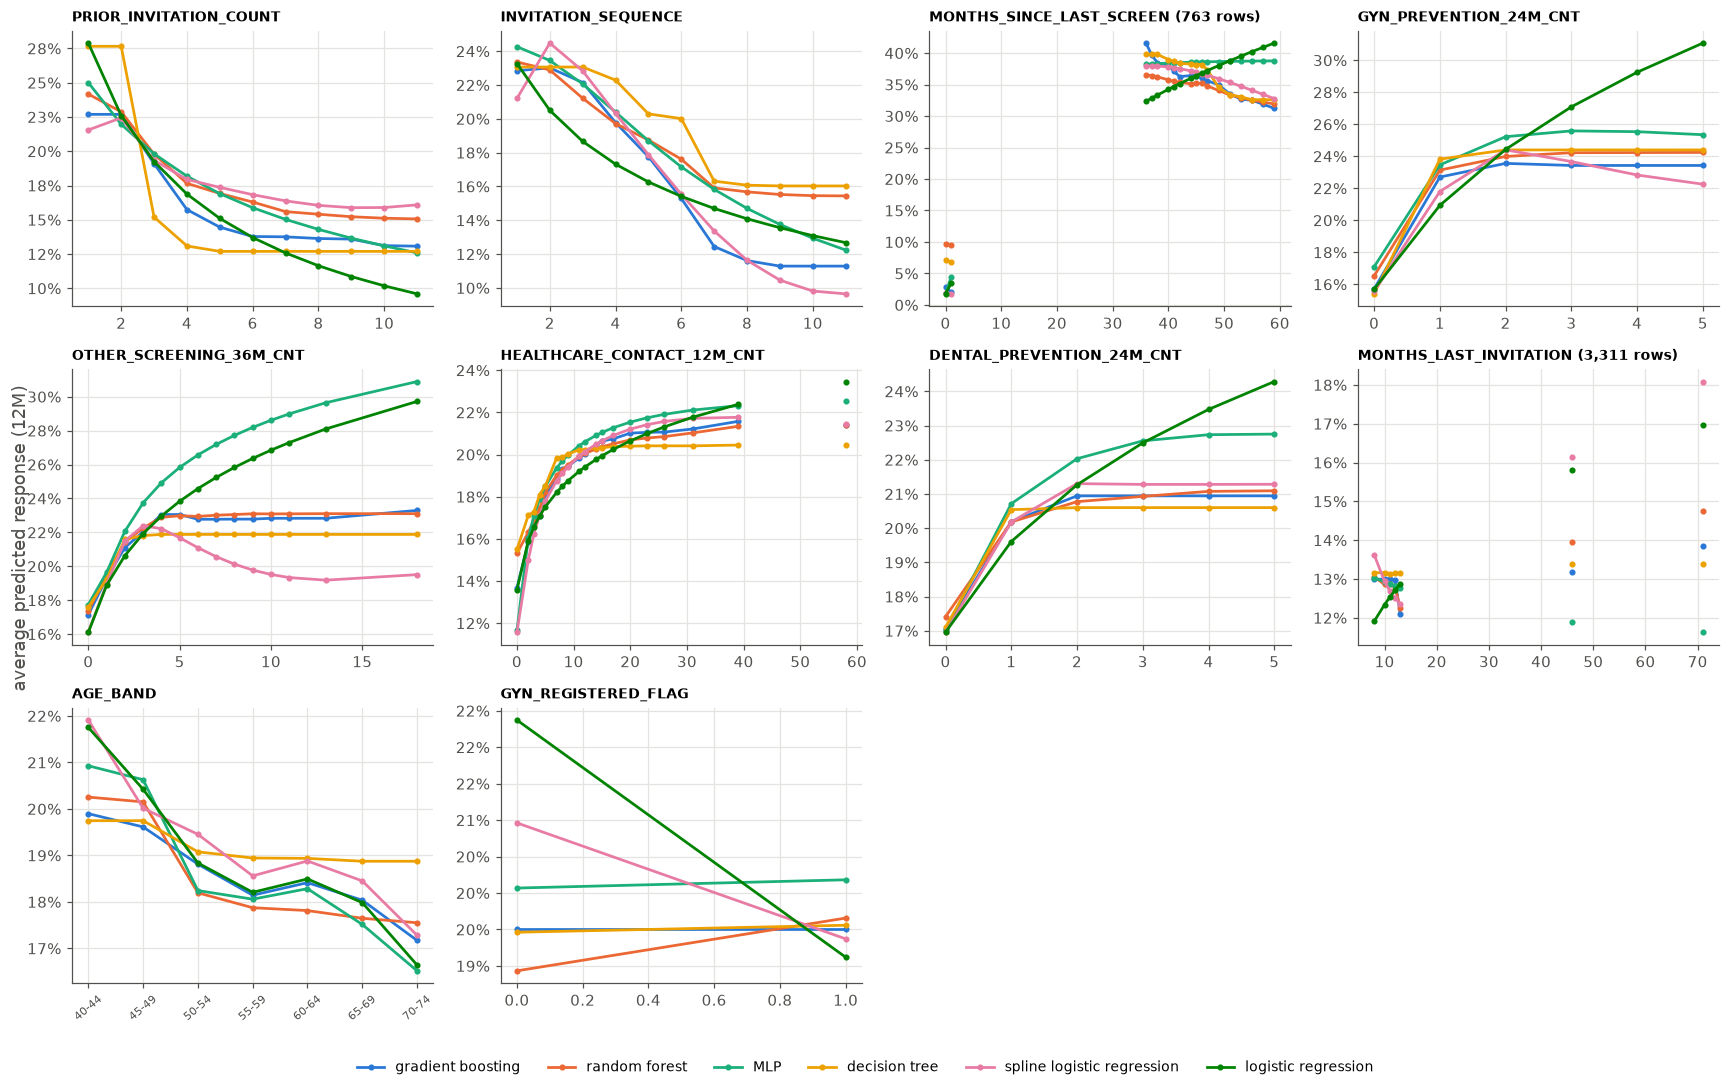

In [9]:
feats = pdp.feature.unique().tolist()
pd_models = pdp.model.unique().tolist()
colors = dict(zip(pd_models, SERIES, strict=False))
ncol = 4
nrow = int(np.ceil(len(feats) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3.3 * nrow))
for ax, feat in zip(axes.flat, feats, strict=False):
    s = pdp[pdp.feature == feat]
    labels = s[s.model == pd_models[0]].value.tolist()
    numeric = feat != "AGE_BAND"
    for m in pd_models:
        t = s[s.model == m]
        xs = t.value.astype(float).to_numpy() if numeric else np.arange(len(t))
        ys = t.mean_prediction.to_numpy()
        if numeric and len(xs) > 2:  # break the line across empty stretches (e.g. 1 -> 36 months)
            gaps = np.diff(xs)
            cut = np.flatnonzero(gaps > 5 * np.median(gaps)) + 1
            xs, ys = np.insert(xs, cut, np.nan), np.insert(ys, cut, np.nan)
        ax.plot(xs, ys, color=colors[m], lw=1.8, marker="o", ms=3, label=m)
    if not numeric:
        ax.set_xticks(np.arange(len(labels)), labels, rotation=40, fontsize=7)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    rows = s.rows.iloc[0]
    ax.set_title(f"{feat}" + ("" if rows == s.rows.max() and feat not in
                              ("MONTHS_SINCE_LAST_SCREEN", "MONTHS_LAST_INVITATION") else f" ({rows:,} rows)"),
                 fontsize=9)
for ax in axes.flat[len(feats):]:
    ax.set_visible(False)
handles, names = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=len(pd_models), fontsize=9)
fig.supylabel("average predicted response (12M)", color=INK2)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

## 4. Logistic regression: odds ratios

Numeric inputs are log-transformed and standardised, so an odds ratio is the change in the odds of being screened per
**one standard deviation** of the (log) feature. One-hot categories are relative to the average category.
OR > 1 = more likely to be screened, OR < 1 = less likely. The 75 area dummies are summarised separately.

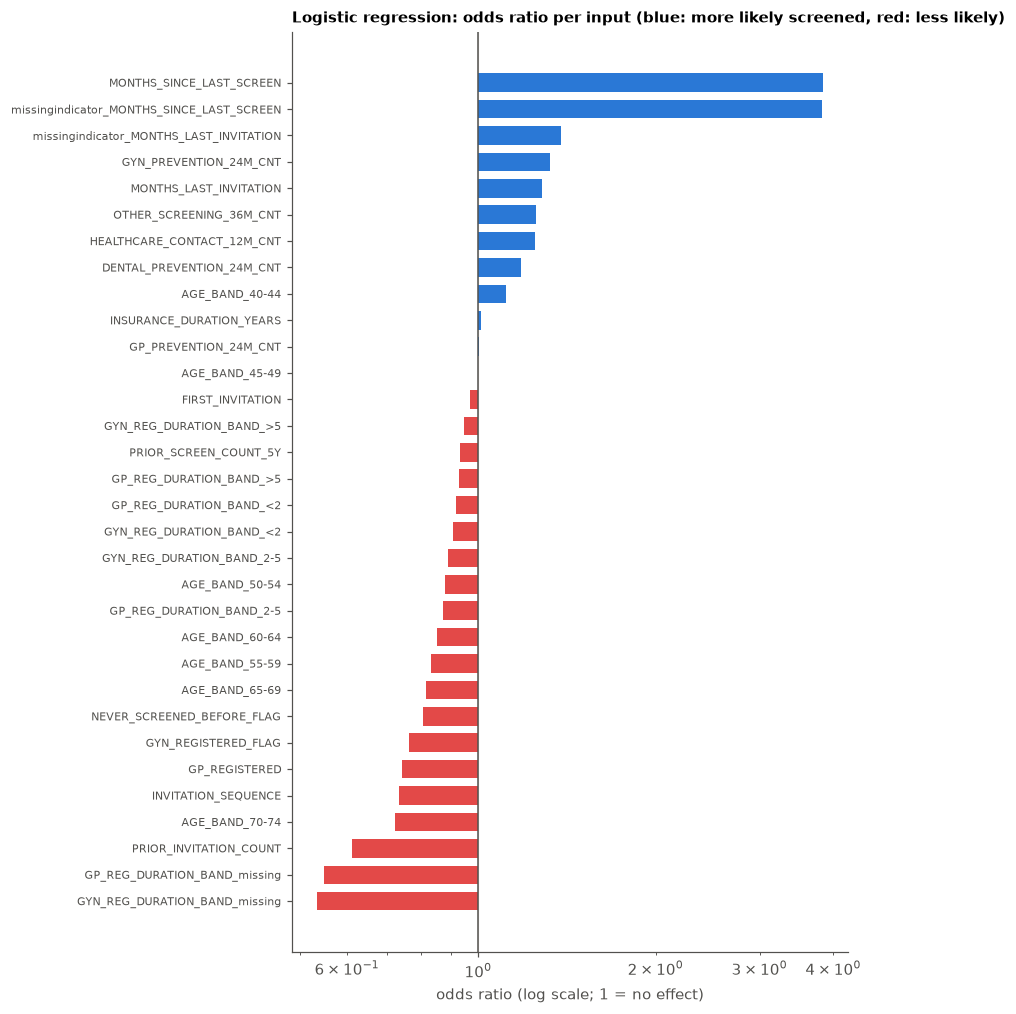

Areas with the highest / lowest odds (other features held equal):


area,odds_ratio
KOLÍN,1.25
BENEŠOV,1.25
BEROUN,1.20
TŘEBÍČ,1.19
TRUTNOV,1.18
KARVINÁ,0.72
JINDŘICHŮV HRADEC,0.73
SEMILY,0.78
ZLÍN,0.82
KLATOVY,0.83


In [10]:
c = coef.copy()
c["group"] = np.select(
    [c.input.str.startswith("VZP_TERRITORIAL_AREA"), c.input.str.startswith("missingindicator")],
    ["area", "missing indicator"], "feature")
main = c[c.group != "area"].sort_values("coefficient")
fig, ax = plt.subplots(figsize=(8, 0.26 * len(main) + 1))
colors_ = np.where(main.coefficient > 0, BLUE, "#e34948")
ax.barh(main.input, main.odds_ratio - 1, left=1, color=colors_, height=0.7)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="y", visible=False)
ax.set_xlabel("odds ratio (log scale; 1 = no effect)")
ax.set_title("Logistic regression: odds ratio per input (blue: more likely screened, red: less likely)")
plt.tight_layout(); plt.show()

area = c[c.group == "area"].assign(area=lambda d: d.input.str.replace("VZP_TERRITORIAL_AREA_", ""))
print("Areas with the highest / lowest odds (other features held equal):")
display(pd.concat([area.nlargest(5, "odds_ratio"), area.nsmallest(5, "odds_ratio")])[["area", "odds_ratio"]]
        .style.format({"odds_ratio": "{:.2f}"}).hide(axis="index"))

## 5. Takeaways

**1. The drawn tree explains most of the model.** A depth-3 tree with 8 leaves reaches test ROC AUC 0.808 (depth 4:
0.822; the full depth-8 tree 0.836; best model 0.841). Its leaves read as simple segments:
- **Most likely to respond (57% screened, 17% of invitations):** at most 2 prior invitations, at least one
  gynaecologist prevention visit in 2 years, and not screened in the last ~12 months.
- **Least likely (4% screened, 39% of invitations):** more than 2 prior invitations, invitation sequence above 4,
  and no gynaecologist prevention visit. This is the largest group of invitations and the least likely to respond.
- **Screened in the last ~12 months (3% screened):** they are not due yet, and the invitation comes too early.
- In between: few invitations but no gynaecologist visit (18–35%, depending on other screening programmes), or
  repeat invitations with a gynaecologist visit (12–26%).

**2. All models rely on the same three drivers.** In every model except naive Bayes, the top predictors are:
- **invitation history** (`PRIOR_INVITATION_COUNT`, `INVITATION_SEQUENCE`): more ignored invitations, less
  response;
- **time since the last screen** (`MONTHS_SINCE_LAST_SCREEN`): for women screened before, response depends mostly
  on whether they are due;
- **gynaecologist prevention** (`GYN_PREVENTION_24M_CNT`), followed by other screening programmes and healthcare
  contact.

The models differ only in how they split importance between the two correlated invitation counters, not in what
matters.

**3. The direction and shape of the effects are consistent across models** (section 3):
- Invitation history: the predicted response falls from about 23% at the 1st–2nd invitation to 10–16% by the
  10th (depending on the model), levelling off after about 6 invitations.
- Months since last screen: about 2–10% if screened 0–1 months before the invitation, a peak of about 37–42% at
  36 months, then (in most models) a slow decline to about 31–33% at 59 months. The effect rises and then falls, which a single
  linear coefficient cannot capture; this is why the spline and tree models beat plain logistic regression.
- Gynaecologist prevention: a jump from 0 to 1 visit (about 16% → 23%), then flat. *Whether* a woman sees a
  gynaecologist preventively matters, not how often.
- Other screening programmes, dental prevention and healthcare contact: smaller, steady increases that flatten out.
- Age: a modest decline, from about 20–22% at 40–44 to about 17% at 70–74. That is far smaller than the raw gap
  (57% vs 10%), because most of the raw age effect runs through invitation history.
- Gynaecologist *registration*: flat in the flexible models once prevention visits are known. The visits matter,
  not the registration.

**4. Logistic regression odds ratios** (per standard deviation of the log feature, other features held equal):
- Lower odds: more prior invitations (OR 0.61), higher invitation sequence (0.74), age 70–74 (0.72).
- Higher odds: gynaecologist prevention (1.33), other screening (1.26), healthcare contact (1.25),
  dental prevention (1.18).
- Location: after the other features, area shifts the odds by about ±25% (Karviná 0.72 … Kolín 1.25).
- Caution: some inputs encode the same fact twice. "Registered" flags and the "missing" registration-band levels
  are an example, as are `MONTHS_SINCE_LAST_SCREEN` and its missing indicator. Their individual odds ratios are
  not meaningful alone; read them as a pair, or use the partial-dependence curves.

**What this means for VZP.** Response is mostly predicted by past behaviour (ignored invitations, prevention visits)
and timing (being due for a screen). Two practical levers stand out: time invitations to when the woman is due
(about 3 years after her last screen), and treat the 39% "chronic non-responder, no gynaecologist" group as a
separate problem. Repeating the same letter does little for them (4% response), so it is the natural target for
different interventions (tasks 3–4).